In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from warnings import filterwarnings 
filterwarnings("ignore")

In [4]:
df = pd.read_excel(r"C:\Users\deytu\Desktop\study\EXCELR\Assignment\Data and Docs\glass.xlsx", sheet_name = "glass")
df

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.00,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.00,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.00,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.00,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.00,0.0,1
...,...,...,...,...,...,...,...,...,...,...
209,1.51623,14.14,0.00,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.00,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.00,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.00,1.94,73.61,0.00,8.48,1.57,0.0,7


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [6]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


### Observations
- The data set has 214 rows and no columns has any null values present
- the target variable "Type" has 7 values from 1 - 7
- Each element has a percentage weight cotribution 

### Data Visualization

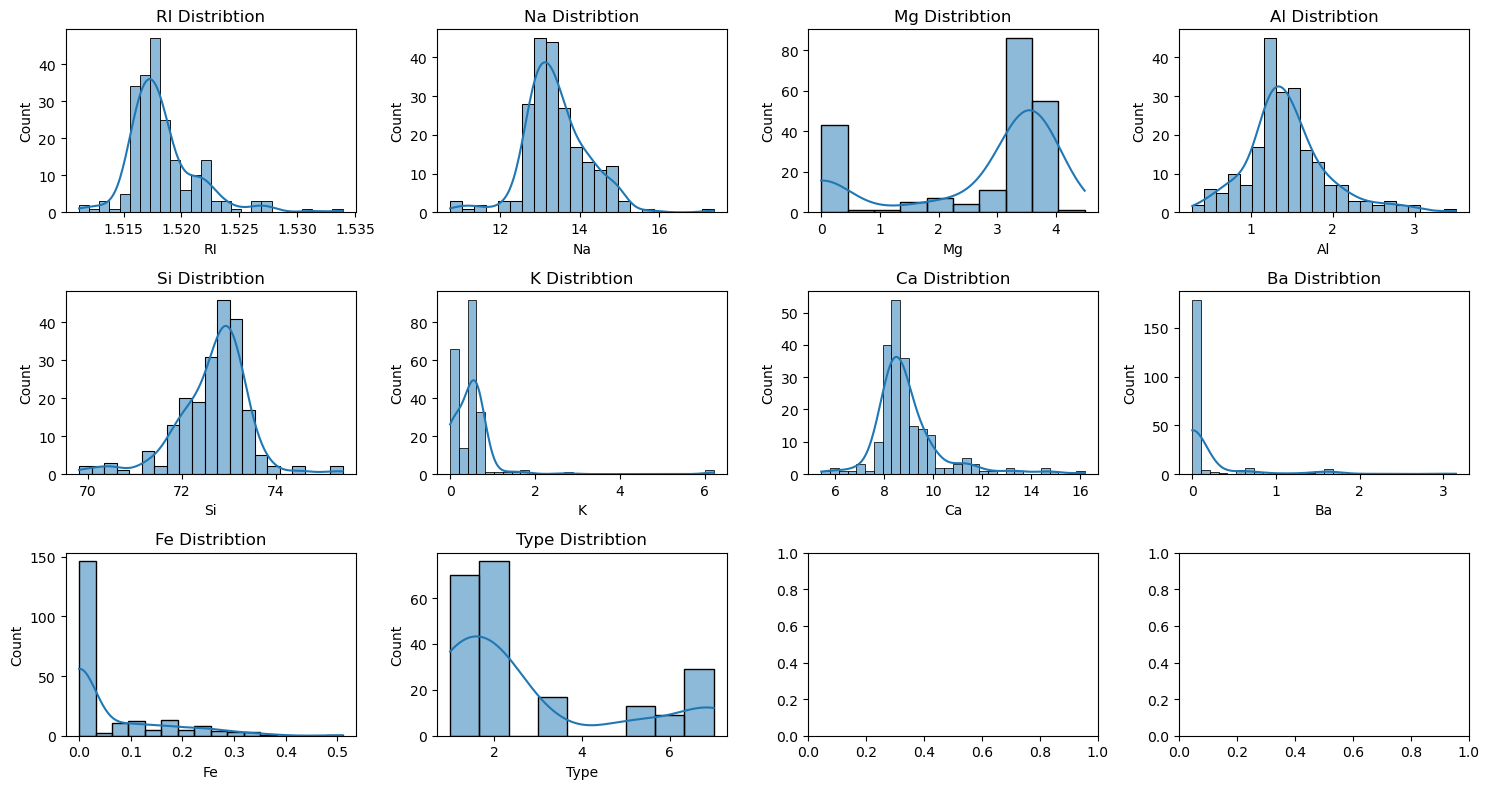

In [10]:
num_cols = ["RI","Na","Mg","Al","Si","K","Ca","Ba","Fe","Type"]
figure , axes = plt.subplots(3,4 , figsize = (15,8))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(data = df , x = col , kde = True , ax = axes[i])
    axes[i].set_title(f"{col} Distribtion")

plt.tight_layout()
plt.show()

### Observation 
- RI , Na , Al , K , Ca ,  Ba  ,Fe distributions are right skewed
- Mg, Si, are left skewed
- Ba , Fe , K have peaks around zero meaning in most cases they are absent

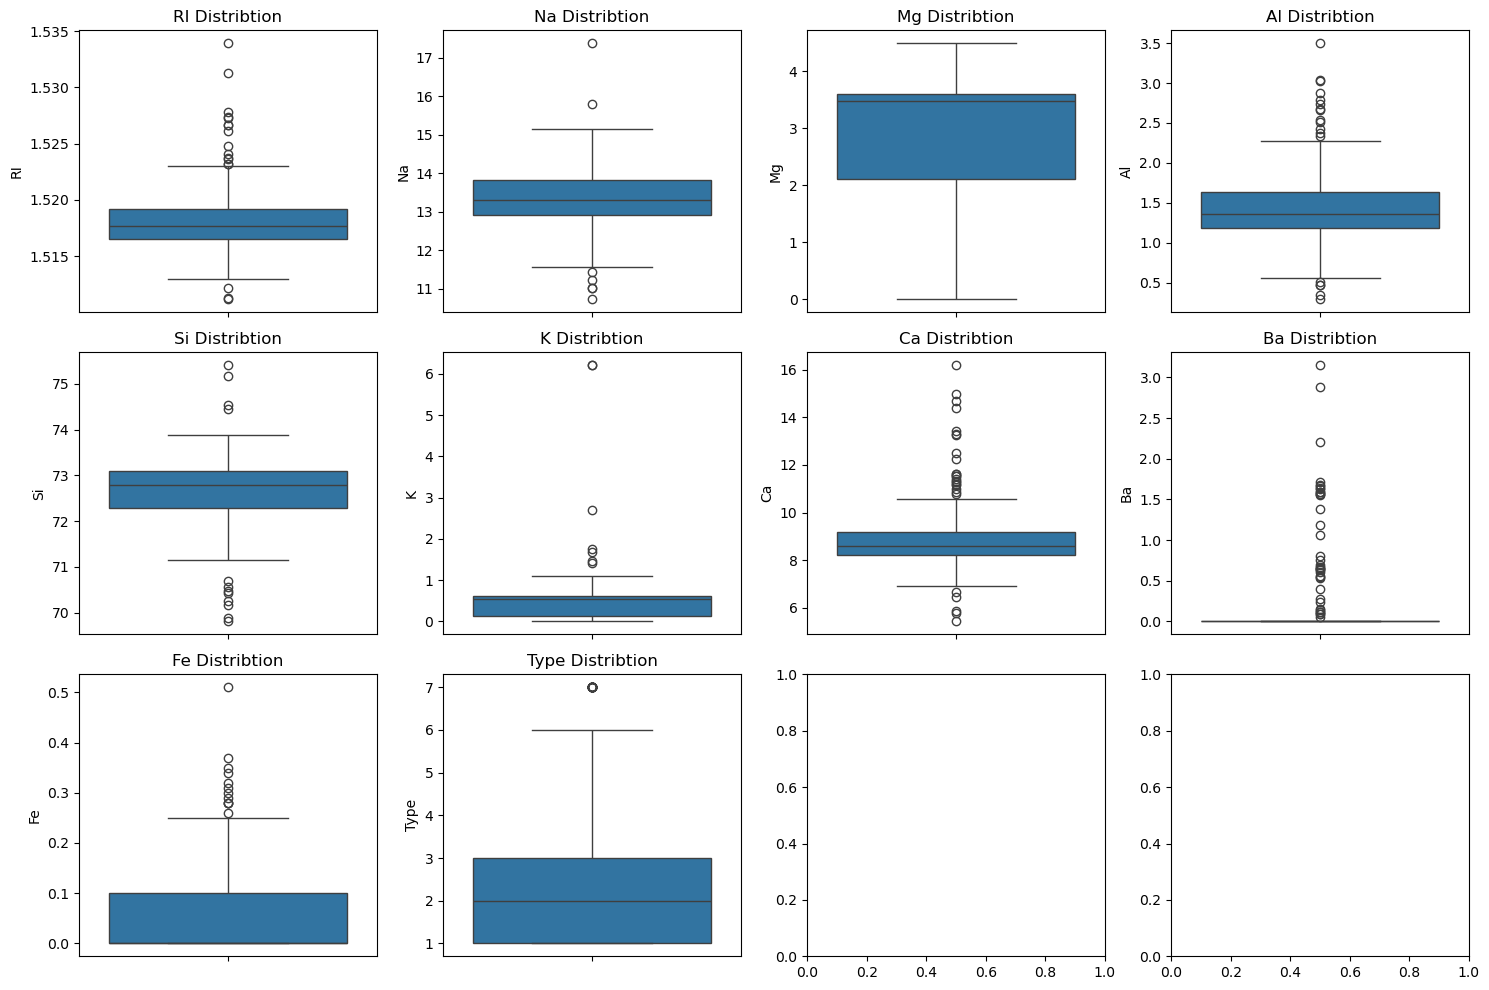

In [12]:
num_cols = ["RI","Na","Mg","Al","Si","K","Ca","Ba","Fe","Type"]
figure , axes = plt.subplots(3,4 , figsize = (15,10))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.boxplot(df[col], ax = axes[i])
    axes[i].set_title(f"{col} Distribtion")

plt.tight_layout()
plt.show()

### Obsrvation 
- outliers are present in all columns baring type 

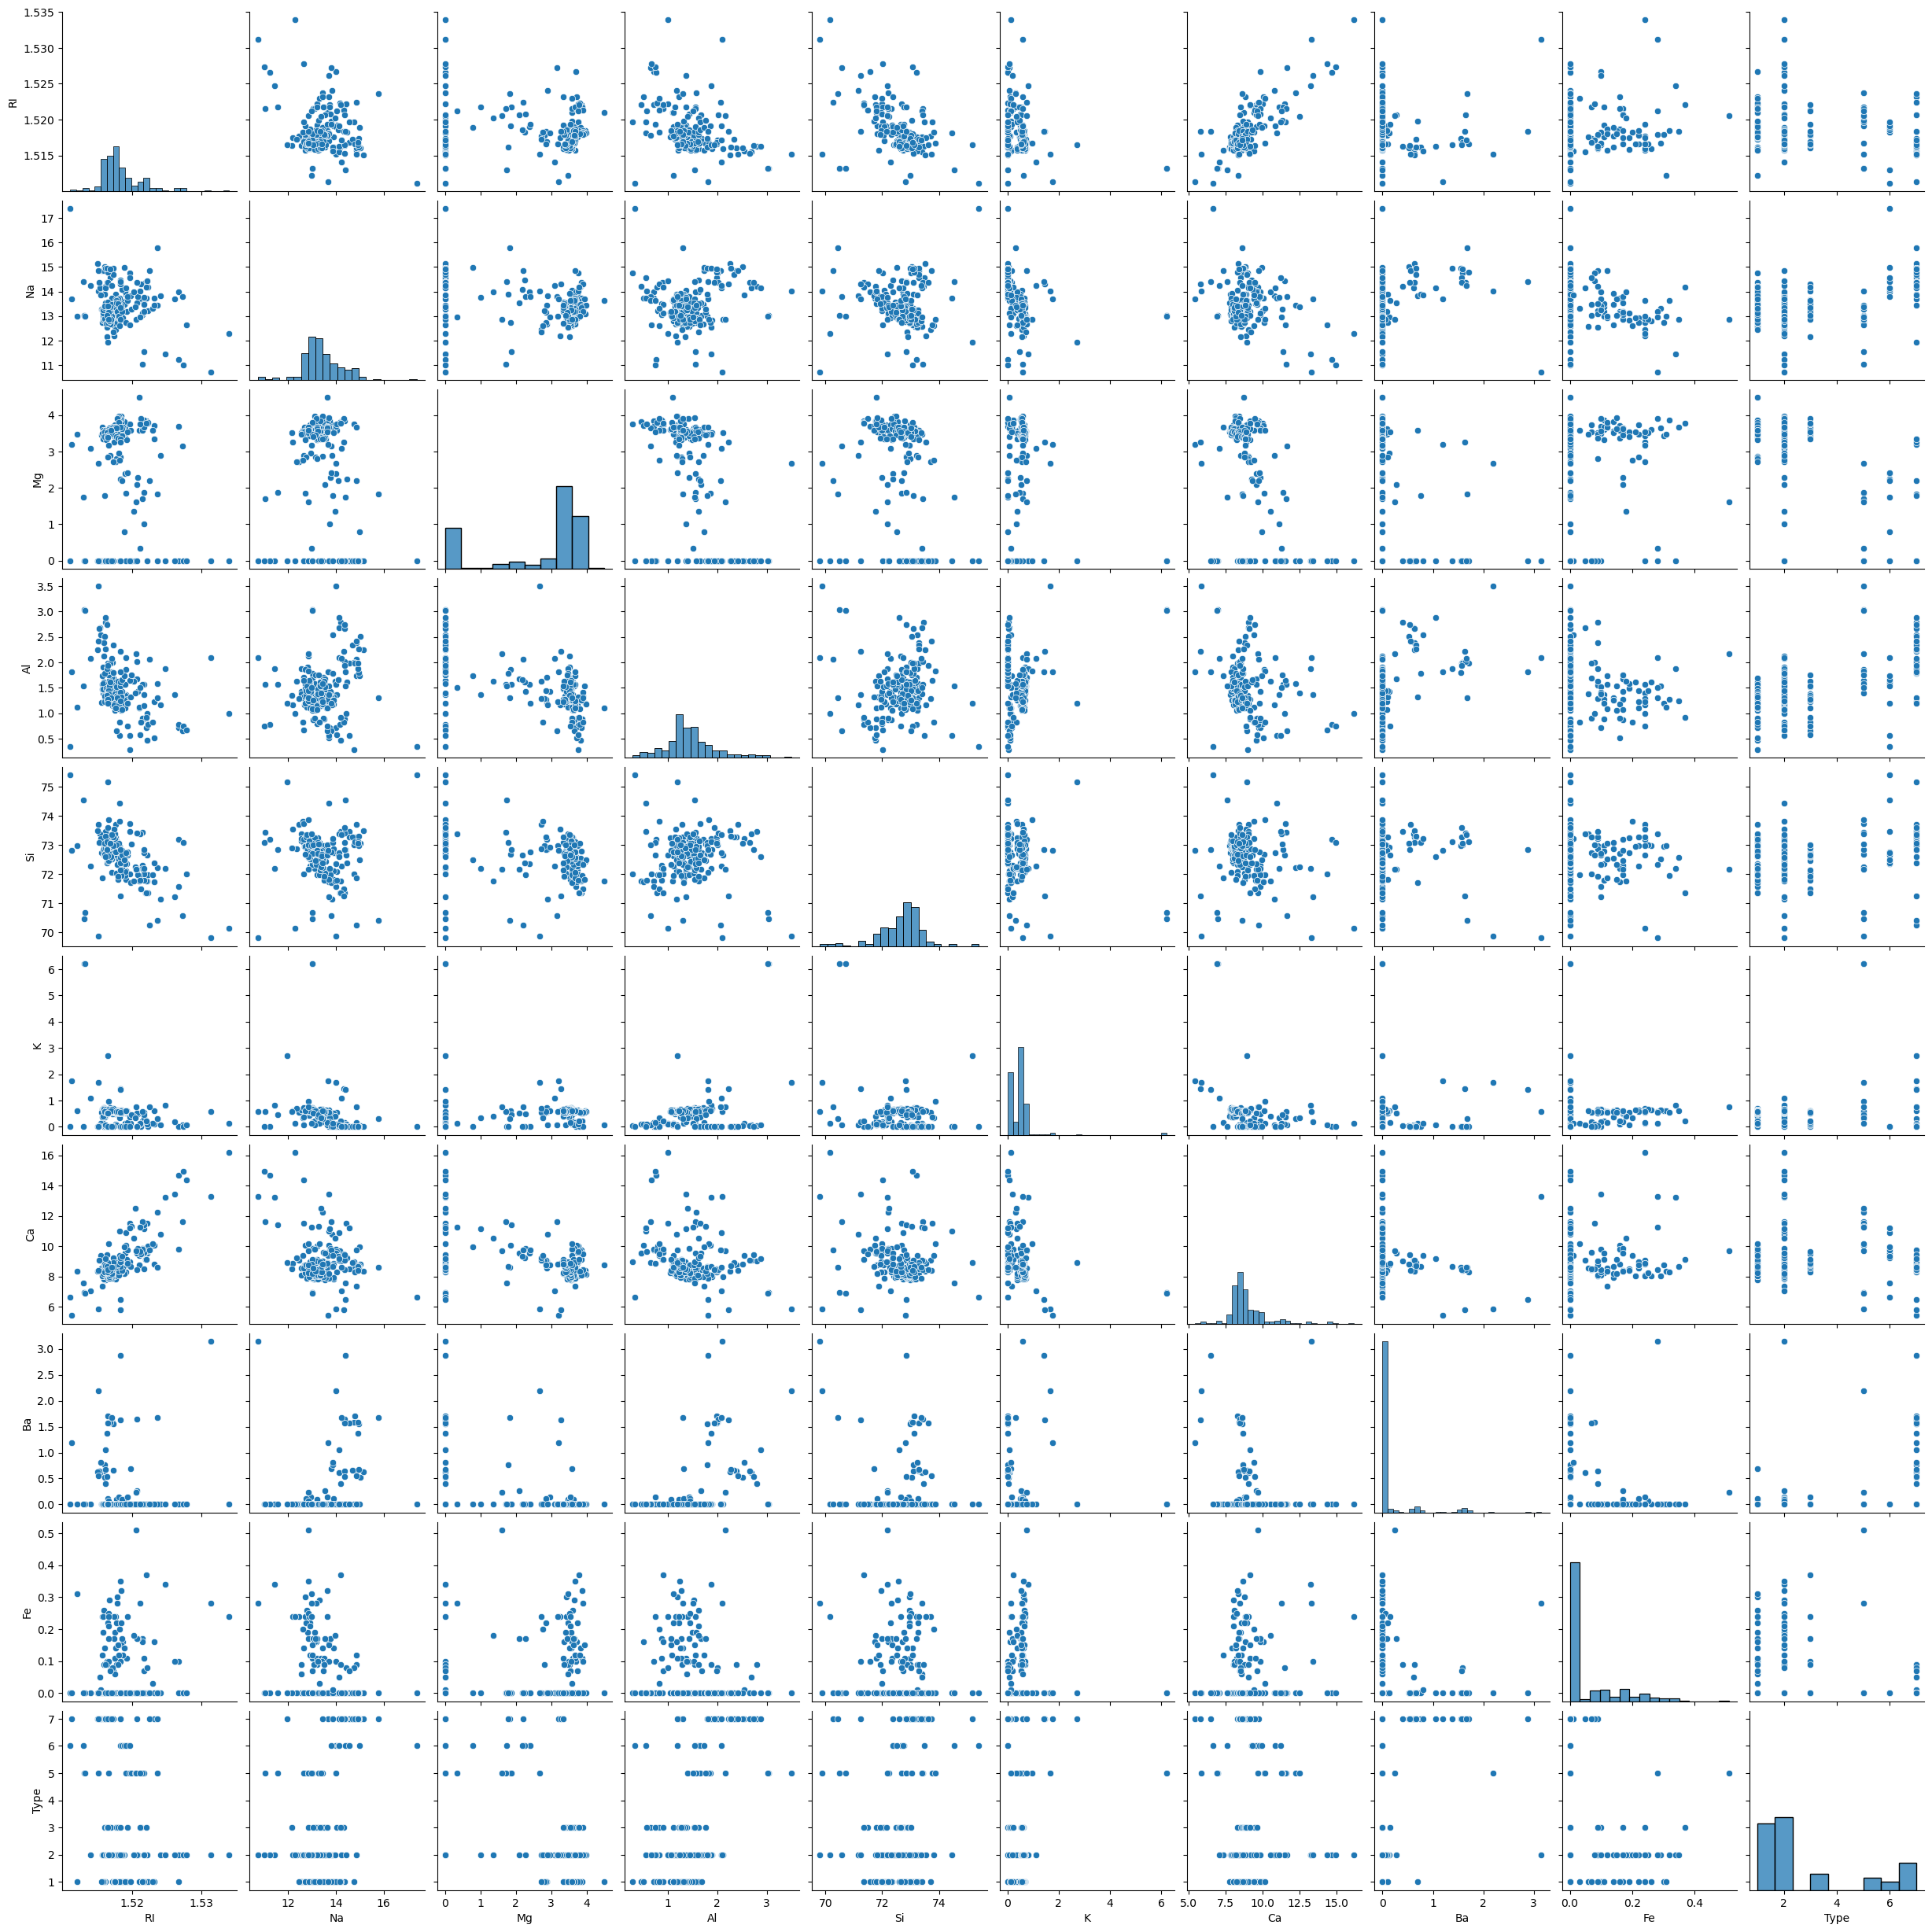

In [13]:
sns.pairplot(df)

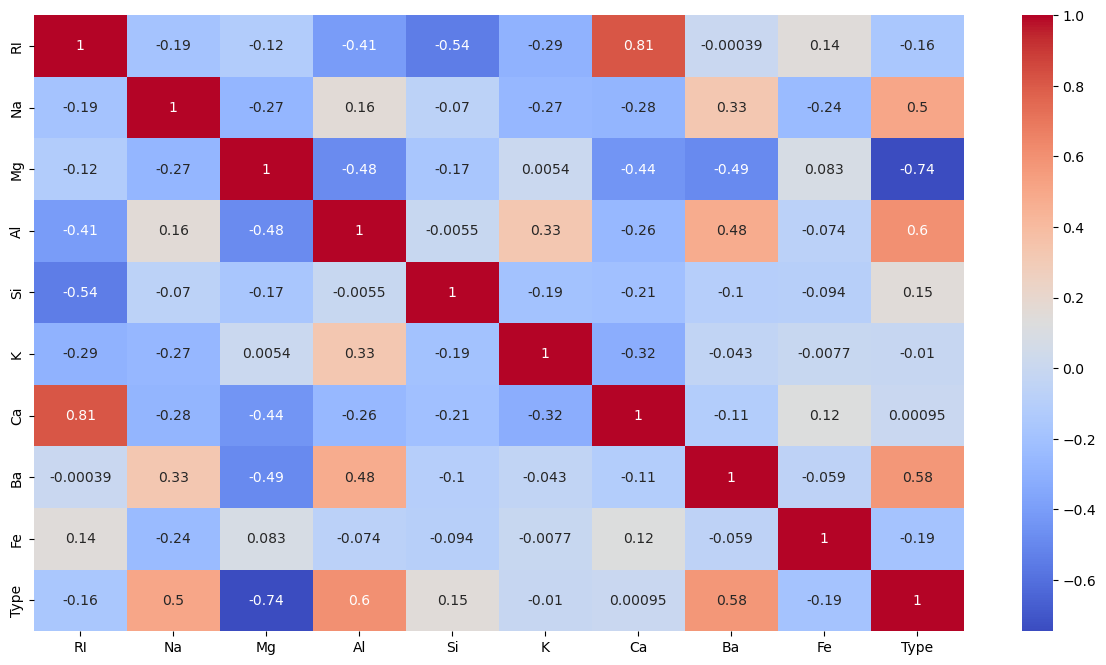

In [15]:
plt.figure(figsize = (15,8))
sns.heatmap(df.corr() , annot = True , cmap = "coolwarm")
plt.show()


### Observations 
- for type (target variable) Mg is negatively correlated 
- while Al , Na , Ba have strong positive correlation with target variable
- RI and Ca have strong positive multicollinearity

### Model Implementation 
- since we are using random forest we wont me needing standardization
- first we will devide the data into train and test split
- since the data is already clean we will not be using any imputation techniques
- no categorical variables are present hence we wont be using any encoding techniques


In [22]:
### Train test split
from sklearn.model_selection import train_test_split
X = df.drop("Type", axis = 1 )
y = df["Type"]

X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 42)
X_train

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
79,1.51590,12.82,3.52,1.90,72.86,0.69,7.97,0.00,0.00
161,1.51934,13.64,3.54,0.75,72.65,0.16,8.89,0.15,0.24
109,1.51818,13.72,0.00,0.56,74.45,0.00,10.99,0.00,0.00
127,1.52081,13.78,2.28,1.43,71.99,0.49,9.85,0.00,0.17
95,1.51860,13.36,3.43,1.43,72.26,0.51,8.60,0.00,0.00
...,...,...,...,...,...,...,...,...,...
106,1.53125,10.73,0.00,2.10,69.81,0.58,13.30,3.15,0.28
14,1.51763,12.61,3.59,1.31,73.29,0.58,8.50,0.00,0.00
92,1.51588,13.12,3.41,1.58,73.26,0.07,8.39,0.00,0.19
179,1.51852,14.09,2.19,1.66,72.67,0.00,9.32,0.00,0.00


In [25]:
## scaling 
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train1 = scaler.fit_transform(X_train)
X_test1 = scaler.fit_transform(X_test)
X_train = pd.DataFrame(X_train1 , columns = X_train.columns , index =X_train.index )
X_train.describe()


,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02,1.710000e+02
mean,-4.155221e-17,1.038805e-17,3.116416e-17,1.558208e-17,2.077610e-17,-1.038805e-17,3.116416e-17,-4.155221e-17,-2.597013e-17
std,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00,1.002937e+00
min,-2.350015e+00,-3.494334e+00,-2.030349e+00,-2.369220e+00,-3.636363e+00,-8.959529e-01,-2.485833e+00,-3.376113e-01,-6.011100e-01
25%,-6.365605e-01,-6.460033e-01,-2.871372e-01,-4.786105e-01,-4.440372e-01,-6.005648e-01,-5.075930e-01,-3.376113e-01,-6.011100e-01
50%,-2.303113e-01,-1.131746e-01,5.045715e-01,-1.425021e-01,2.022620e-01,1.065763e-01,-2.492539e-01,-3.376113e-01,-6.011100e-01
75%,2.676715e-01,5.249041e-01,5.917321e-01,3.721639e-01,5.613170e-01,1.960878e-01,2.072632e-01,-3.376113e-01,3.929887e-01
max,5.060756e+00,3.162735e+00,1.230910e+00,4.373955e+00,3.375003e+00,1.022138e+01,5.129862e+00,5.793688e+00,4.468793e+00


In [26]:
X_test = pd.DataFrame(X_test1 , columns = X_test.columns , index =X_test.index )
X_test.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe
count,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01,4.300000e+01
mean,-8.947623e-15,-1.633706e-15,-1.420053e-16,-6.454785e-17,7.416548e-15,-2.194627e-17,-2.175263e-16,1.032766e-17,-1.239319e-16
std,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00,1.011835e+00
min,-2.333756e+00,-2.479335e+00,-1.412124e+00,-2.146610e+00,-3.149773e+00,-5.195694e-01,-1.636511e+00,-4.336952e-01,-5.343813e-01
25%,-5.630098e-01,-5.206348e-01,-1.412124e+00,-6.329905e-01,-4.975663e-01,-4.550918e-01,-4.501893e-01,-4.336952e-01,-5.343813e-01
50%,-1.203232e-01,-1.850007e-01,5.890556e-01,-7.534131e-02,1.671308e-01,-1.112113e-01,-1.769549e-01,-4.336952e-01,-5.343813e-01
75%,3.898039e-01,5.263433e-01,8.344832e-01,4.380500e-01,5.159323e-01,1.359527e-01,7.552757e-02,-4.336952e-01,-4.022225e-02
max,3.282830e+00,3.892703e+00,9.351715e-01,2.633241e+00,3.339250e+00,6.153861e+00,4.111788e+00,3.654716e+00,2.924732e+00


In [28]:
## Model implementation 
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators = 100,random_state = 42)
model.fit(X_train , y_train)
y_pred = model.predict(X_test)

In [31]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
acc = accuracy_score(y_pred,y_test)
cm = confusion_matrix(y_pred ,y_test)
cr = classification_report(y_pred , y_test)
print("Accuracy", acc)
print("\n Confusion matrix\n", cm)
print("\nClassification Report\n" , cr)



Accuracy 0.6046511627906976

 Confusion matrix
 [[6 5 2 0 0 0]
 [5 9 1 2 0 0]
 [0 0 0 0 1 0]
 [0 0 0 2 1 0]
 [0 0 0 0 1 0]
 [0 0 0 0 0 8]]

Classification Report
               precision    recall  f1-score   support

           1       0.55      0.46      0.50        13
           2       0.64      0.53      0.58        17
           3       0.00      0.00      0.00         1
           5       0.50      0.67      0.57         3
           6       0.33      1.00      0.50         1
           7       1.00      1.00      1.00         8

    accuracy                           0.60        43
   macro avg       0.50      0.61      0.53        43
weighted avg       0.65      0.60      0.62        43



## Random Forest Performance Analysis

- The model achieved an overall accuracy of 60.47%, indicating moderate classification performance.
- Class 7 was classified perfectly, with 100% precision, recall, and F1-score.
- Classes 1 and 2 achieved moderate performance, with F1-scores of 0.50 and 0.58, respectively.
- Class 5 was reasonably identified despite having only three samples in the test set.
- Class 3 was not classified correctly, resulting in zero precision, recall, and F1-score.
- Class 6 achieved 100% recall but only 33% precision because several predictions for this class were incorrect.
- The confusion matrix shows that the model frequently confused Classes 1 and 2, suggesting that these classes have similar feature characteristics.
- The weighted F1-score of 0.62 indicates moderate overall predictive performance.
- The macro average is lower than the weighted average because minority classes have very few samples, making them difficult for the model to learn.
- The poor performance on Classes 3 and 6 is mainly due to severe class imbalance, as these classes contain very few observations.

### Bagging and Boosting

In [32]:
### bagging 
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

bagging = BaggingClassifier(estimator = DecisionTreeClassifier(random_state = 42 ), n_estimators = 100 , random_state = 42)
bagging.fit(X_train,y_train)
y_pred = bagging.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report\n", classification_report(y_test, y_pred))

Accuracy: 0.5581395348837209

Confusion Matrix
 [[5 6 0 0 0 0]
 [6 8 0 0 0 0]
 [0 3 0 0 0 0]
 [0 2 0 2 0 0]
 [0 1 0 1 1 0]
 [0 0 0 0 0 8]]

Classification Report
               precision    recall  f1-score   support

           1       0.45      0.45      0.45        11
           2       0.40      0.57      0.47        14
           3       0.00      0.00      0.00         3
           5       0.67      0.50      0.57         4
           6       1.00      0.33      0.50         3
           7       1.00      1.00      1.00         8

    accuracy                           0.56        43
   macro avg       0.59      0.48      0.50        43
weighted avg       0.56      0.56      0.54        43



In [34]:
from sklearn.ensemble import AdaBoostClassifier
ada = AdaBoostClassifier(
    n_estimators=100,
    learning_rate=1.0,
    random_state=42
)
ada.fit(X_train,y_train)
y_pred = ada.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report\n", classification_report(y_test, y_pred))

Accuracy: 0.5581395348837209

Confusion Matrix
 [[9 2 0 0 0 0]
 [4 9 1 0 0 0]
 [2 1 0 0 0 0]
 [0 3 0 1 0 0]
 [1 0 0 2 0 0]
 [0 0 0 3 0 5]]

Classification Report
               precision    recall  f1-score   support

           1       0.56      0.82      0.67        11
           2       0.60      0.64      0.62        14
           3       0.00      0.00      0.00         3
           5       0.17      0.25      0.20         4
           6       0.00      0.00      0.00         3
           7       1.00      0.62      0.77         8

    accuracy                           0.56        43
   macro avg       0.39      0.39      0.38        43
weighted avg       0.54      0.56      0.53        43



In [37]:
from sklearn.ensemble import GradientBoostingClassifier
gb = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
gb.fit(X_train,y_train)
y_pred = gb.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report\n", classification_report(y_test, y_pred))

Accuracy: 0.6046511627906976

Confusion Matrix
 [[ 4  7  0  0  0  0]
 [ 2 12  0  0  0  0]
 [ 0  2  1  0  0  0]
 [ 0  3  0  1  0  0]
 [ 0  2  0  0  0  1]
 [ 0  0  0  0  0  8]]

Classification Report
               precision    recall  f1-score   support

           1       0.67      0.36      0.47        11
           2       0.46      0.86      0.60        14
           3       1.00      0.33      0.50         3
           5       1.00      0.25      0.40         4
           6       0.00      0.00      0.00         3
           7       0.89      1.00      0.94         8

    accuracy                           0.60        43
   macro avg       0.67      0.47      0.49        43
weighted avg       0.65      0.60      0.56        43



## Comparison of Ensemble Models

| Metric | Random Forest | Gradient Boosting | Bagging |
|--------|---------------:|------------------:|---------:|
| Accuracy | **60.47%** | **60.47%** | **55.81%** |
| Weighted Precision | 0.65 | 0.65 | 0.56 |
| Weighted Recall | 0.60 | 0.60 | 0.56 |
| Weighted F1-score | **0.62** | 0.56 | 0.54 |
| Macro F1-score | **0.53** | 0.49 | 0.50 |
| Best Classified Class | Class 7 | Class 7 | Class 7 |
| Worst Classified Class | Class 3 | Class 6 | Class 3 |

## Observations

- Random Forest and Gradient Boosting achieved the highest accuracy (60.47%).
- Random Forest produced the highest weighted F1-score (0.62), indicating the best overall balance between precision and recall.
- Gradient Boosting matched the accuracy of Random Forest but had a lower weighted F1-score because it struggled more with minority classes.
- Bagging achieved the lowest accuracy (55.81%) and weighted F1-score (0.54), making it the weakest performer among the three models.
- All three models classified Class 7 very accurately, indicating that this class is easily distinguishable from the others.
## Conclusion

- Random Forest provided the best overall performance with the highest weighted F1-score while maintaining the highest accuracy.
- Gradient Boosting achieved the same accuracy as Random Forest but was less effective on minority classes.
- Bagging showed the lowest overall performance and was more affected by class imbalance.
- The performance of all three models was limited by the small size and imbalanced nature of the Glass dataset. Hyperparameter tuning, stratified cross-validation, and class imbalance handling could further improve the results.

### 1. Explain Bagging and Boosting methods. How are they different?

Bagging and Boosting are ensemble learning techniques that combine multiple models to improve prediction accuracy.

- Bagging trains multiple models independently on different random samples of the dataset and combines their predictions using voting or averaging. It mainly reduces variance and helps prevent overfitting.
- Boosting trains models one after another, where each new model focuses on correcting the mistakes of the previous one. It mainly reduces bias and improves overall accuracy.

Difference:
- Bagging trains models independently, while Boosting trains models sequentially.
- Bagging reduces variance, whereas Boosting reduces bias and variance.
- Bagging is generally less prone to overfitting than Boosting.

### 2. Explain how to handle imbalance in the data.

Class imbalance can be handled using several techniques:

- Oversampling: Increase the number of samples in the minority class using methods like SMOTE.
- Undersampling: Reduce the number of samples in the majority class.
- Class weights: Assign higher importance to minority classes during model training.
- Collect more data: Gather additional samples for the minority classes if possible.
- Use suitable evaluation metrics: Instead of accuracy alone, use precision, recall, F1-score, and ROC-AUC to evaluate model performance.